In [2]:
# imports
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

# load data
d = sio.loadmat('/Users/diyasajlar/sense-cgsense/data/kneePD.mat')
ksp = np.transpose(d['kspace'], (1, 2, 0))
S = np.transpose(d['coils'], (1, 2, 0))
nx, ny, nc = ksp.shape

# fft2c and ifft2c (fourier transform and inverse fourier transform)
def fft2c(x):
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(x, axes=(0,1)), axes=(0,1), norm='ortho'), axes=(0,1))
def ifft2c(x):
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(x, axes=(0,1)), axes=(0,1), norm='ortho'), axes=(0,1))

coil_imgs = ifft2c(ksp)



0.97268534 0.0001090161
1.0


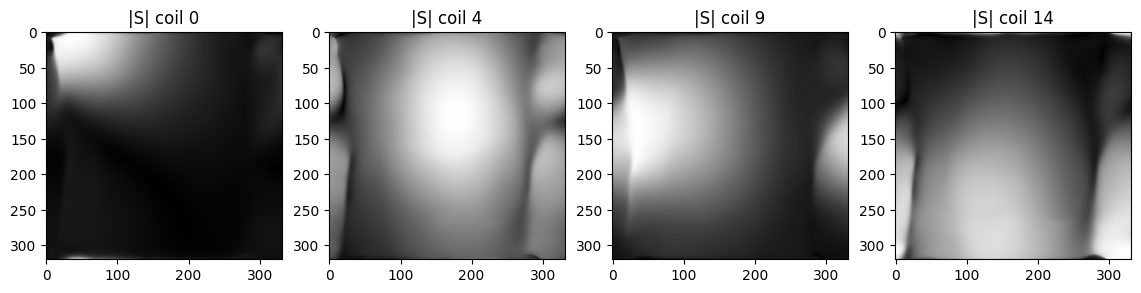

In [3]:
# sensitivity maps
print(np.abs(S).max(), np.abs(S).min())
print(np.sum(np.abs(S)**2, axis=2).mean())   # ~1 if normalized sensitivities
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
for i, c in enumerate([0, 4, 9, 14]):
    ax[i].imshow(np.abs(S[:, :, c]), cmap='gray'); ax[i].set_title(f'|S| coil {c}')
plt.show()

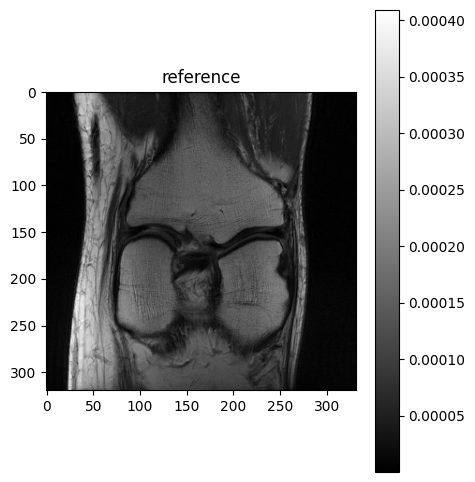

In [ ]:
# least-squares coil combination: finds rho such that coil_imgs ≈ S * rho
ref = np.sum(np.conj(S) * coil_imgs, axis=2) / (np.sum(np.abs(S)**2, axis=2) + 1e-8)

plt.figure(figsize=(5, 6))
plt.imshow(np.abs(ref), cmap='gray'); plt.title('reference'); plt.colorbar()
plt.axis('off')
plt.show()

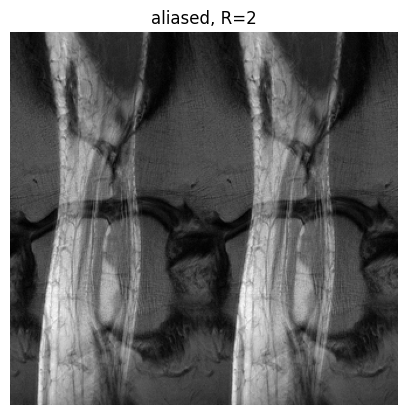

In [5]:
# folding aliasing
R = 2
ky = np.arange(ny) - ny//2
mask = (ky % R == 0).astype(float)[None, :, None]   # keeps every R-th line along axis 1
ksp_us = ksp * mask
alias = ifft2c(ksp_us)

plt.figure(figsize=(5, 6))
plt.imshow(np.sqrt(np.sum(np.abs(alias)**2, axis=2)), cmap='gray')
plt.title(f'aliased, R={R}')
plt.axis('off')
plt.show()

In [7]:
def sense_unfold(alias, S, R, lam=1e-6):
    nx, ny, nc = S.shape
    nyr = ny // R
    Sm = S.reshape(nx, R, nyr, nc).transpose(0, 2, 3, 1)        # (nx, nyr, nc, R)
    a  = R * alias[:, :nyr, :]                                   # undo the 1/R scaling
    A  = np.einsum('xycr,xycs->xyrs', Sm.conj(), Sm)             # S^H S
    rhs = np.einsum('xycr,xyc->xyr', Sm.conj(), a)               # S^H a
    eps = lam * np.max(np.trace(A, axis1=2, axis2=3).real) / R   # regularize empty pixels
    Areg = A + eps * np.eye(R)
    v = np.linalg.solve(Areg, rhs[..., None])[..., 0]            # (nx, nyr, R)
    Ainv = np.linalg.inv(Areg)
    g = np.sqrt(np.abs(np.einsum('xyrr->xyr', Ainv) * np.einsum('xyrr->xyr', A)))
    rho = v.transpose(0, 2, 1).reshape(nx, ny)
    g   = g.transpose(0, 2, 1).reshape(nx, ny)
    return rho, g

In [8]:
rho, g = sense_unfold(alias, S, R)

# normalized root mean square error
def nrmse(a, b):
    return np.linalg.norm(np.abs(a) - np.abs(b)) / np.linalg.norm(np.abs(b))

# Test A: simulate aliased data directly from the model, then unfold it
alias_sim = ifft2c(fft2c(S * ref[..., None]) * mask)
rho_test, _ = sense_unfold(alias_sim, S, R)
print('synthetic NRMSE:', nrmse(rho_test, ref))   # should be tiny (~1e-3 or less)

# Test B: the real data
print('real-data NRMSE:', nrmse(rho, ref))

synthetic NRMSE: 1.4328249432035177e-06
real-data NRMSE: 0.034865703797357844


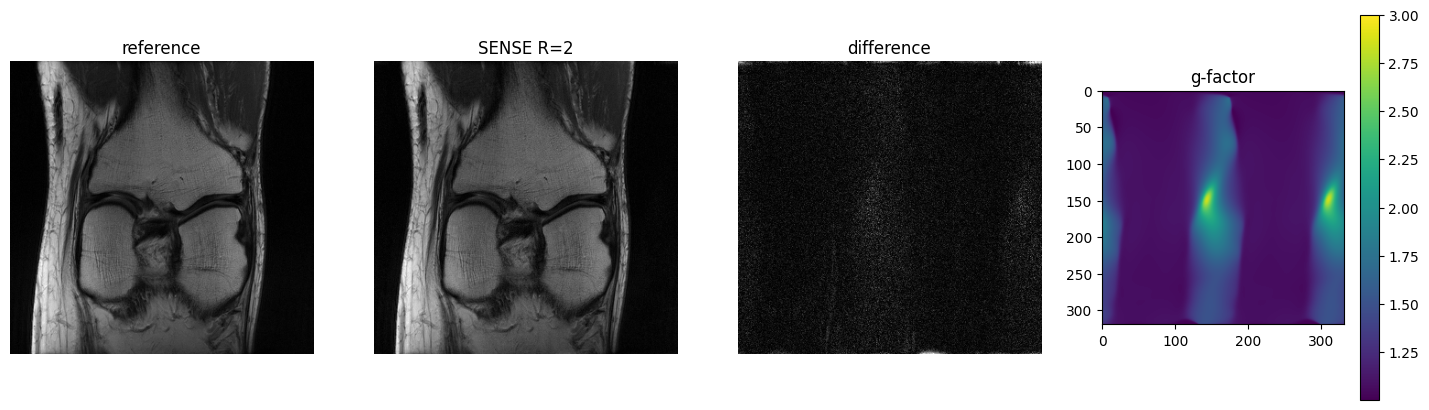

In [15]:
# plot generation (left to right: reference, SENSE, difference, g-factor)
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].axis('off')
ax[0].imshow(np.abs(ref), cmap='gray');  ax[0].set_title('reference')
ax[1].axis('off')
ax[1].imshow(np.abs(rho), cmap='gray');  ax[1].set_title(f'SENSE R={R}')
ax[2].axis('off')
ax[2].imshow(np.abs(np.abs(rho) - np.abs(ref)), cmap='gray'); ax[2].set_title('difference')
im = ax[3].imshow(g, cmap='viridis', vmax=3); ax[3].set_title('g-factor')
fig.colorbar(im, ax=ax[3])
plt.show()